# **Project Name**    - User Gender Classification (Travel MLOps Capstone)

##### **Project Type**    - Classification
##### **Contribution**    - Individual
##### **Team Member 1 -** Anson Sibi

# **Project Summary -**

Knowing a customer's gender helps a travel platform personalise offers, plan marketing and fill gaps in customer profiles. In our data, a third of the users never declared it. In this notebook I built a classification model that predicts a user's gender (male / female) and deployed it as part of the same MLOps system as the flight price model: a Flask endpoint, a Streamlit page and MLflow tracking.

**Data.** `users.csv` has 1,340 users with `code`, `company`, `name`, `gender` and `age`. The labels are split almost evenly: 452 male, 448 female and **440 "none"** (not declared). I joined `flights.csv` and `hotels.csv` through `userCode` to build travel-behaviour features (number of flights, average ticket price, share of first-class tickets, hotel nights and spend).

**Key findings from the EDA and hypothesis tests.**
* Age is the same across genders (Kruskal–Wallis p ≈ 0.62), and gender is independent of company (χ² p ≈ 0.37).
* Travel behaviour (flights, class, hotel stays) is also the same for men and women. A model trained on these features scores **≈ 48% accuracy**, no better than a coin flip.
* The **first name** carries the signal: 167 of the 169 first names ending in "a" are female (χ² p ≈ 10⁻⁴⁵).
* "none" is not a third gender that can be learned: the *same* first names appear under "none" and under male/female. So I trained on male/female only, and the model answers **"uncertain"** when its confidence is below 60%.

**Text preprocessing.** The input is the user's name, so I applied NLP steps to it: whitespace trimming, lower-casing, removing punctuation and digits, extracting the first name, adding start/end markers (`^maria$`) and **character n-gram TF-IDF vectorisation**. This lets the model learn prefixes and suffixes like "-a", "-ine" and "jo-" that generalise to names it has never seen.

**Models.** I compared (1) Logistic Regression on travel-behaviour features (baseline), (2) Multinomial Naive Bayes on character n-grams and (3) Logistic Regression on character n-grams, each tuned with GridSearchCV and stratified 5-fold CV. The final model is the **character n-gram Logistic Regression** (accuracy ≈ 0.89, macro-F1 ≈ 0.89, ROC-AUC ≈ 0.96 on the test set). On first names it has never seen, it still scores ≈ 0.74. The coefficients are easy to read: endings like "a$" push towards female.

**Deployment.** The model is retrained by the Airflow pipeline, logged to MLflow (experiment `gender-classification`, registered model `gender-classifier`), served by the Flask API at `POST /predict/gender` and available in the Streamlit app.

# **GitHub Link -**

https://github.com/ansonsibi/travel-mlops-capstone

# **Problem Statement**

**Build a classification model that predicts a user's gender** from the information in the users dataset (and, where useful, their travel history), so that the platform can complete customer profiles where gender is missing. The model must report its confidence and avoid guessing when the evidence is weak.

# **General Guidelines** : -

1.   Well-structured, formatted, and commented code is required.
2.   Exception Handling, Production Grade Code & Deployment Ready Code will be a plus. Those students will be awarded some additional credits.

     The additional credits will have advantages over other students during Star Student selection.

             [ Note: - Deployment Ready Code is defined as, the whole .ipynb notebook should be executable in one go
                       without a single error logged. ]

3.   Each and every logic should have proper comments.
4. You may add as many number of charts you want. Make Sure for each and every chart the following format should be answered.

```
# Chart visualization code
```

*   Why did you pick the specific chart?
*   What is/are the insight(s) found from the chart?
* Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

5. You have to create at least 15 logical & meaningful charts having important insights.

[ Hints : - Do the Vizualization in  a structured way while following "UBM" Rule.

U - Univariate Analysis,

B - Bivariate Analysis (Numerical - Categorical, Numerical - Numerical, Categorical - Categorical)

M - Multivariate Analysis
 ]

6. You may add more ml algorithms for model creation. Make sure for each and every algorithm, the following format should be answered.

*   Explain the ML Model used and it's performance using Evaluation metric Score Chart.

*   Cross- Validation & Hyperparameter Tuning

*   Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

*   Explain each evaluation metric's indication towards business and the business impact pf the ML model used.

# ***Let's Begin !***

## ***1. Know Your Data***

### Import Libraries

In [1]:
# Import Libraries
import os
import re
import string
import warnings

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, RocCurveDisplay, accuracy_score, classification_report,
                             f1_score, precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import GridSearchCV, GroupKFold, StratifiedKFold, cross_val_score, train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (10, 5)
RANDOM_STATE = 42

### Dataset Loading

In [2]:
# The notebook works both locally (repo checkout) and on Google Colab.
# Locally it reads ../data/raw/, on Colab it downloads the same CSVs from the GitHub repo.
GITHUB_RAW = "https://raw.githubusercontent.com/ansonsibi/travel-mlops-capstone/main/data/raw/"
LOCAL_DIR = "../data/raw/"


def read_dataset(file_name: str) -> pd.DataFrame:
    """Read a CSV from the local repo if present, otherwise from GitHub."""
    local_path = os.path.join(LOCAL_DIR, file_name)
    source = local_path if os.path.exists(local_path) else GITHUB_RAW + file_name
    try:
        return pd.read_csv(source)
    except Exception as exc:  # network issues / wrong path
        raise RuntimeError(f"Could not load {file_name} from {source}: {exc}")


# Load Dataset
users = read_dataset("users.csv")
flights = read_dataset("flights.csv")
hotels = read_dataset("hotels.csv")

### Dataset First View

In [3]:
# Dataset First Look
users.head(10)

,code,company,name,gender,age
0,0,4You,Roy Braun,male,21
1,1,4You,Joseph Holsten,male,37
2,2,4You,Wilma Mcinnis,female,48
3,3,4You,Paula Daniel,female,23
4,4,4You,Patricia Carson,female,44
5,5,4You,Trina Thomas,none,47
6,6,4You,Jesse Decelle,male,46
7,7,4You,Gregoria Gil,female,21
8,8,4You,Jack Sabo,none,41
9,9,4You,Debbie Helms,none,35


### Dataset Rows & Columns count

In [4]:
# Dataset Rows & Columns count
for name, data in [("users", users), ("flights", flights), ("hotels", hotels)]:
    print(f"{name:<8} rows: {data.shape[0]:>7,}  columns: {data.shape[1]}")

users    rows:   1,340  columns: 5
flights  rows: 271,888  columns: 10
hotels   rows:  40,552  columns: 8


### Dataset Information

In [5]:
# Dataset Info
users.info()

<class 'pandas.DataFrame'>
RangeIndex: 1340 entries, 0 to 1339
Data columns (total 5 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   code     1340 non-null   int64
 1   company  1340 non-null   str  
 2   name     1340 non-null   str  
 3   gender   1340 non-null   str  
 4   age      1340 non-null   int64
dtypes: int64(2), str(3)
memory usage: 88.3 KB


#### Duplicate Values

In [6]:
# Dataset Duplicate Value Count
print("duplicate rows:", users.duplicated().sum())
print("duplicate user codes:", users["code"].duplicated().sum())
print("duplicate full names:", users["name"].duplicated().sum())

duplicate rows: 0
duplicate user codes: 0
duplicate full names: 2


#### Missing Values/Null Values

In [7]:
# Missing Values/Null Values Count
users.isnull().sum()

code       0
company    0
name       0
gender     0
age        0
dtype: int64

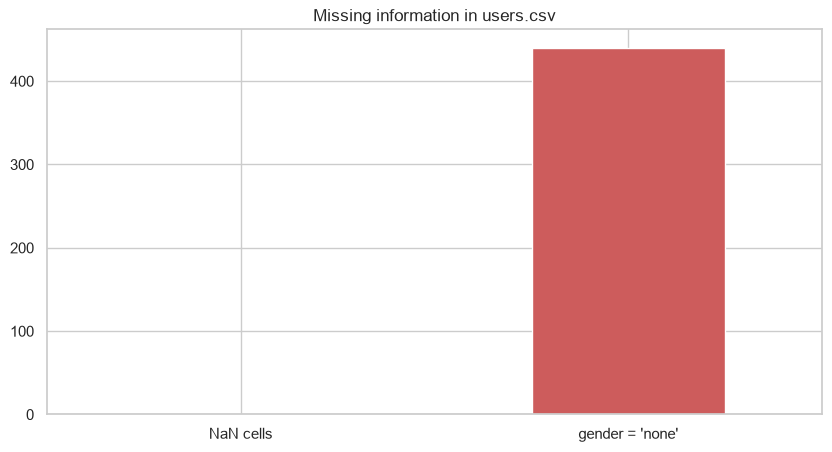

In [8]:
# Visualizing the missing values
# there are no NaN cells, but gender "none" is a *missing label* in disguise
missing = pd.Series({"NaN cells": int(users.isnull().sum().sum()),
                     "gender = 'none'": int((users["gender"] == "none").sum())})
missing.plot(kind="bar", color=["grey", "indianred"], rot=0)
plt.title("Missing information in users.csv")
plt.show()

### What did you know about your dataset?

* `users.csv` has **1,340 rows and 5 columns** (`code`, `company`, `name`, `gender`, `age`), with no NaN cells and no duplicate rows or codes. Two full names appear twice (different people with the same name).
* `gender` has three values: male (452), female (448) and **none (440)**. "none" behaves like a missing label, so the real classification target is male vs female.
* `flights.csv` (271,888 legs) and `hotels.csv` (40,552 stays) can be joined on `userCode` to describe each user's travel behaviour.

## ***2. Understanding Your Variables***

In [9]:
# Dataset Columns
list(users.columns)

['code', 'company', 'name', 'gender', 'age']

In [10]:
# Dataset Describe
users.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
code,1340.0,NaN,NaN,NaN,669.5,386.968991,0.0,334.75,669.5,1004.25,1339.0
company,1340,5,4You,453,NaN,NaN,NaN,NaN,NaN,NaN,NaN
name,1340,1338,David Robinson,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,1340,3,male,452,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,1340.0,NaN,NaN,NaN,42.742537,12.869779,21.0,32.0,42.0,54.0,65.0


### Variables Description 

| Variable | Type | Description |
|---|---|---|
| `code` | int (ID) | User identifier, the key that links to `userCode` in flights and hotels. |
| `company` | categorical | Employer of the user (5 companies), since this is corporate travel. |
| `name` | text | Full name, always "First Last". |
| `gender` | categorical | **Target**: male / female / none (not declared). |
| `age` | int | Age in years (21–65). |

### Check Unique Values for each variable.

In [11]:
# Check Unique Values for each variable.
for col in users.columns:
    print(f"{col:<8} {users[col].nunique():>5} unique values")
print()
print(users["gender"].value_counts())
print(users["company"].value_counts())

code      1340 unique values
company      5 unique values
name      1338 unique values
gender       3 unique values
age         45 unique values

gender
male      452
female    448
none      440
Name: count, dtype: int64
company
4You             453
Acme Factory     261
Wonka Company    237
Monsters CYA     195
Umbrella LTDA    194
Name: count, dtype: int64


## 3. ***Data Wrangling***

### Data Wrangling Code

In [12]:
# Write your code to make your dataset analysis ready.
users["first_name"] = users["name"].str.strip().str.split().str[0]
users["last_name"] = users["name"].str.strip().str.split().str[-1]
users["first_len"] = users["first_name"].str.len()
users["last_letter"] = users["first_name"].str[-1].str.lower()
users["ends_with_vowel"] = users["last_letter"].isin(list("aeiou")).astype(int)
users["age_band"] = pd.cut(users["age"], bins=[20, 30, 40, 50, 65], labels=["21-30", "31-40", "41-50", "51-65"])

# travel behaviour per user (joined via userCode)
flight_feats = flights.groupby("userCode").agg(
    n_flights=("travelCode", "count"), avg_ticket=("price", "mean"),
    first_class_share=("flightType", lambda s: (s == "firstClass").mean()), avg_distance=("distance", "mean"))
hotel_feats = hotels.groupby("userCode").agg(n_hotel_stays=("travelCode", "count"), avg_nights=("days", "mean"),
                                              hotel_spend=("total", "sum"))
users = users.join(flight_feats, on="code").join(hotel_feats, on="code")
BEHAVIOUR = ["n_flights", "avg_ticket", "first_class_share", "avg_distance", "n_hotel_stays", "avg_nights",
             "hotel_spend"]
users[BEHAVIOUR] = users[BEHAVIOUR].fillna(0)    # users with no trips get zero activity

labelled = users[users["gender"].isin(["male", "female"])].copy()
unlabelled = users[users["gender"] == "none"].copy()
print("labelled:", len(labelled), "| not declared:", len(unlabelled))

# how ambiguous are first names across the three labels?
labels_per_name = users.groupby("first_name")["gender"].agg(lambda s: tuple(sorted(set(s))))
labels_per_name.value_counts()

labelled: 900 | not declared: 440


gender
(female,)               193
(male,)                 137
(none,)                 132
(female, none)           78
(male, none)             70
(female, male)            4
(female, male, none)      2
Name: count, dtype: int64

### What all manipulations have you done and insights you found?

**Manipulations**
* Split the name into `first_name`/`last_name` and derived `first_len`, `last_letter`, `ends_with_vowel` and `age_band`.
* Aggregated each user's flights and hotel stays into 7 behaviour features (trip counts, average ticket, first-class share, distance, hotel nights and spend). Users without trips get zeros.
* Separated the **900 labelled** users (male/female) from the **440 "none"** users.

**Insights**
* There are 616 distinct first names. Most belong to a single label, but **150 names appear both as "none" and as male/female**: the same first name is female in one row and "none" in another. So "none" depends on whether the user chose to declare a gender, not on the name, and can't be learned as a class.
* Only 6 first names are used for both male and female, so the first name is a strong, almost unambiguous signal.

## ***4. Data Vizualization, Storytelling & Experimenting with charts : Understand the relationships between variables***

#### Chart - 1 - Gender label distribution (Univariate)

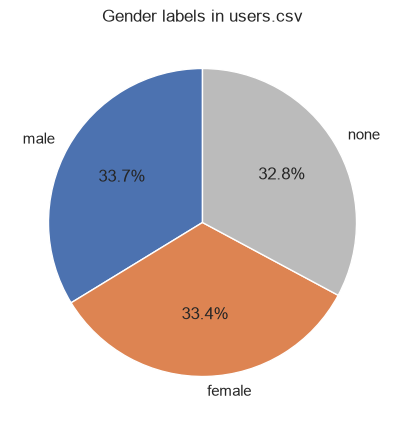

In [13]:
# Chart - 1 visualization code
counts = users["gender"].value_counts()
plt.pie(counts, labels=counts.index, autopct="%1.1f%%", startangle=90, colors=["#4C72B0", "#DD8452", "#BBBBBB"])
plt.title("Gender labels in users.csv")
plt.show()

##### 1. Why did you pick the specific chart?

A pie chart shows how the whole user base splits across the three labels at a glance.

##### 2. What is/are the insight(s) found from the chart?

The labels are almost evenly split: male 33.7%, female 33.4% and **none 32.8%**. One in three users has no declared gender.

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. A third of the customer profiles are incomplete, which limits personalisation, so a model that can fill these gaps (with a confidence score) adds value. The balance between male and female also means the model won't be biased towards one class.

#### Chart - 2 - Age distribution (Univariate)

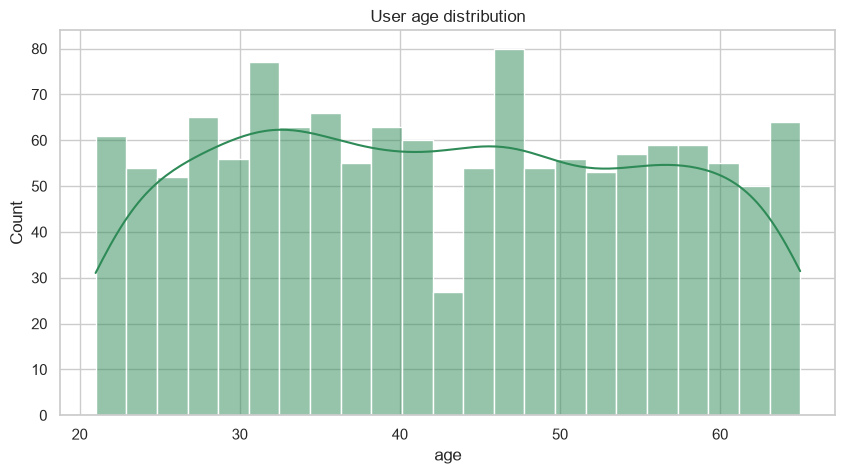

count    1340.0
mean       42.7
std        12.9
min        21.0
25%        32.0
50%        42.0
75%        54.0
max        65.0
Name: age, dtype: float64


In [14]:
# Chart - 2 visualization code
sns.histplot(users["age"], bins=23, kde=True, color="seagreen")
plt.title("User age distribution")
plt.show()
print(users["age"].describe().round(1))

##### 1. Why did you pick the specific chart?

A histogram with a KDE shows the shape and range of a numeric variable.

##### 2. What is/are the insight(s) found from the chart?

Ages are spread almost uniformly between 21 and 65 (mean ≈ 42.7). This is a working-age population, consistent with corporate travellers.

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. Offers should target working professionals (business-friendly hotels, fast check-in) rather than students or retirees. There are no ages outside a plausible range, so no data-quality issues.

#### Chart - 3 - Age by gender (Bivariate: numeric vs categorical)

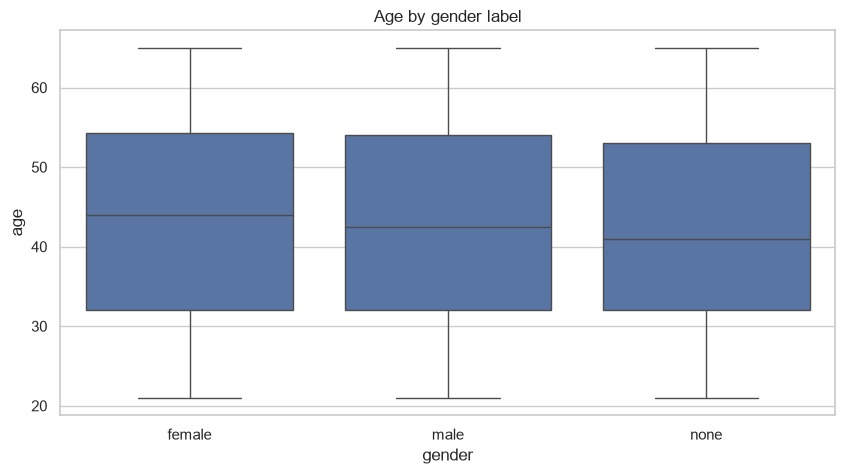

In [15]:
# Chart - 3 visualization code
sns.boxplot(data=users, x="gender", y="age", order=["female", "male", "none"])
plt.title("Age by gender label")
plt.show()

##### 1. Why did you pick the specific chart?

Box plots compare the distribution of a numeric variable across groups.

##### 2. What is/are the insight(s) found from the chart?

The three boxes are almost identical (median ≈ 41–44). Age doesn't differ by gender, so it won't help the classifier (confirmed in Hypothesis 1).

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

Age-based targeting doesn't need to be gender-specific. For modelling, age alone can't predict gender. No negative impact.

#### Chart - 4 - Users per company (Univariate)

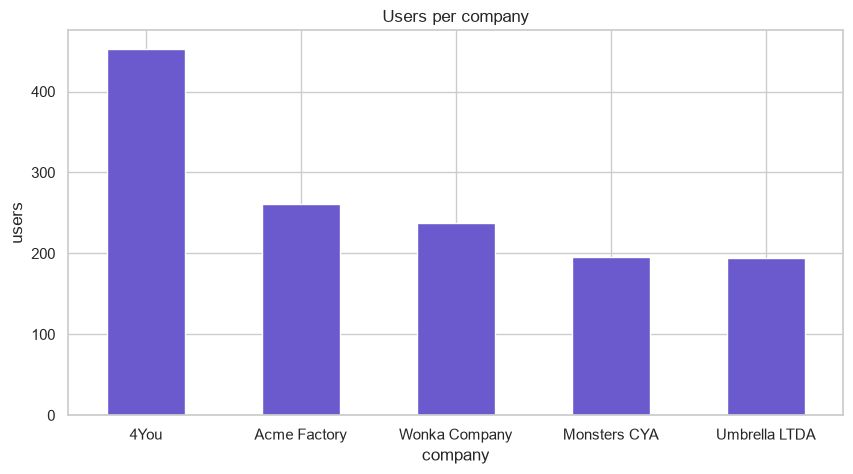

In [16]:
# Chart - 4 visualization code
users["company"].value_counts().plot(kind="bar", color="slateblue", rot=0)
plt.title("Users per company")
plt.ylabel("users")
plt.show()

##### 1. Why did you pick the specific chart?

A bar chart compares counts across a handful of categories.

##### 2. What is/are the insight(s) found from the chart?

4You is the largest client (453 users, ≈ 34%), followed by Acme Factory (261). The other three companies have ≈ 195–237 users each.

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. 4You is the key account, and losing it would cost a third of the user base (a concentration risk). Growing the smaller accounts would reduce that dependence.

#### Chart - 5 - Gender mix per company (Categorical vs categorical)

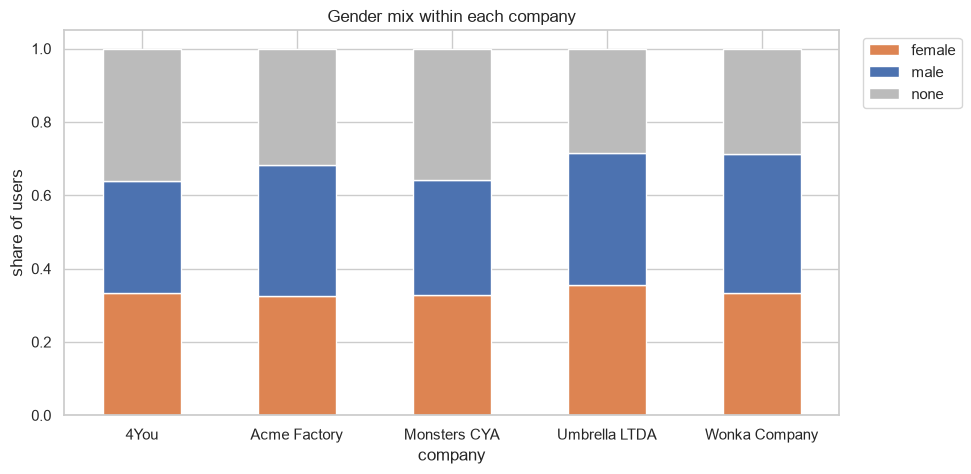

In [17]:
# Chart - 5 visualization code
mix = pd.crosstab(users["company"], users["gender"], normalize="index")
mix.plot(kind="bar", stacked=True, color=["#DD8452", "#4C72B0", "#BBBBBB"], rot=0)
plt.ylabel("share of users")
plt.title("Gender mix within each company")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.show()

##### 1. Why did you pick the specific chart?

A 100% stacked bar compares category proportions across groups regardless of group size.

##### 2. What is/are the insight(s) found from the chart?

Every company has roughly one third male, one third female and one third none. Company doesn't tell us anything about gender (Hypothesis 2).

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. Gender-balanced travel across clients means offers don't need company-specific gender targeting. For modelling, company is not a useful predictor.

#### Chart - 6 - First-name length by gender (Numeric vs categorical)

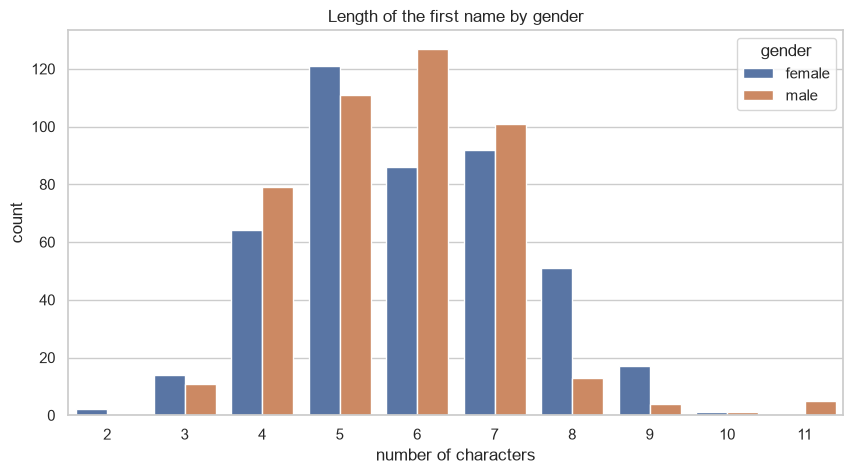

In [18]:
# Chart - 6 visualization code
sns.countplot(data=labelled, x="first_len", hue="gender")
plt.title("Length of the first name by gender")
plt.xlabel("number of characters")
plt.show()

##### 1. Why did you pick the specific chart?

A grouped count plot compares a small discrete numeric variable across two classes.

##### 2. What is/are the insight(s) found from the chart?

Female first names are slightly longer on average (5.9 vs 5.7 characters), but the distributions overlap almost completely. Length alone is a weak signal.

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

Not directly. It tells us that crude name statistics are not enough, which motivates the richer character n-gram features.

#### Chart - 7 - Last letter of the first name by gender (Categorical vs categorical)

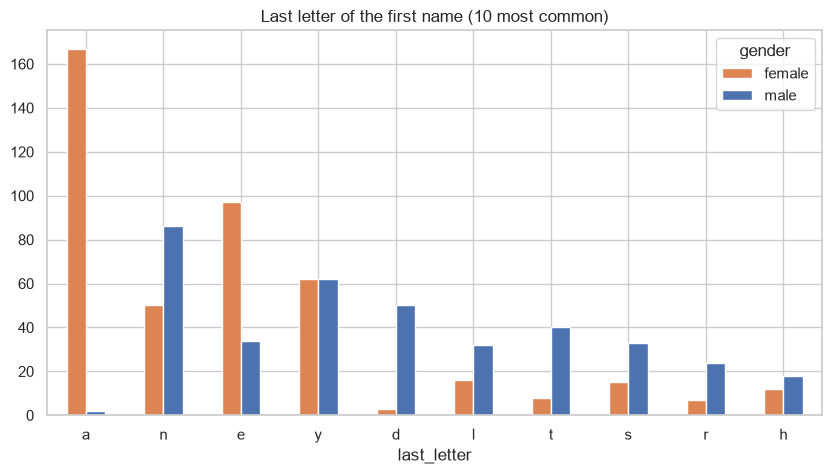

In [19]:
# Chart - 7 visualization code
top_letters = labelled["last_letter"].value_counts().head(10).index
ct = pd.crosstab(labelled["last_letter"], labelled["gender"]).loc[top_letters]
ct.plot(kind="bar", rot=0, color=["#DD8452", "#4C72B0"])
plt.title("Last letter of the first name (10 most common)")
plt.show()

##### 1. Why did you pick the specific chart?

A grouped bar chart shows how each category (last letter) splits between the two classes.

##### 2. What is/are the insight(s) found from the chart?

The last letter is very informative: **names ending in "a" are 99% female (167 vs 2)**, "e" and "i" lean female, while "n", "l", "s" and "h" lean male. "y" is split evenly.

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. This is the key insight: the spelling of the first name carries the gender signal, so character-level features can build an accurate classifier. It also shows where the model will struggle ("y" endings), which is why it reports confidence.

#### Chart - 8 - Most common first names (Univariate)

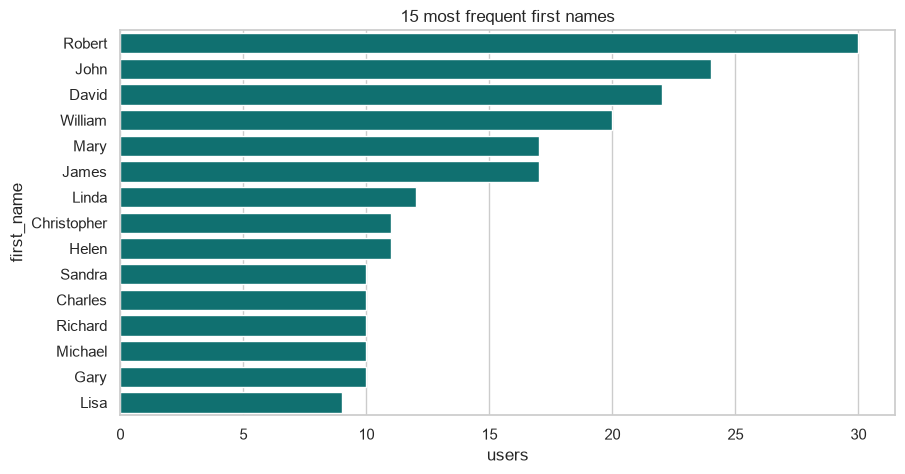

In [20]:
# Chart - 8 visualization code
top_names = users["first_name"].value_counts().head(15)
sns.barplot(x=top_names.values, y=top_names.index, orient="h", color="teal")
plt.title("15 most frequent first names")
plt.xlabel("users")
plt.show()

##### 1. Why did you pick the specific chart?

A horizontal bar chart is the clearest way to rank text categories.

##### 2. What is/are the insight(s) found from the chart?

The most common first names (Robert 30, John 24, David 22, William 20, Mary 17) appear many times. Names repeat, so a random train/test split will contain many names the model has already seen.

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

For the business, these are common US-style first names. For modelling, it means I also need a **group split by first name** to measure accuracy on genuinely new names.

#### Chart - 9 - How ambiguous are first names? (Categorical)

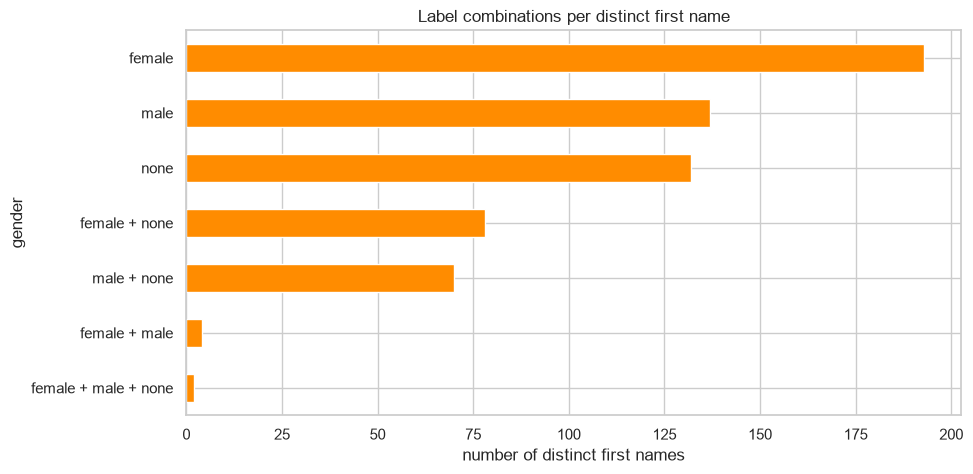

In [21]:
# Chart - 9 visualization code
ambiguity = labels_per_name.map(lambda t: " + ".join(t)).value_counts()
ambiguity.plot(kind="barh", color="darkorange")
plt.title("Label combinations per distinct first name")
plt.xlabel("number of distinct first names")
plt.gca().invert_yaxis()
plt.show()

##### 1. Why did you pick the specific chart?

A bar chart of the label combinations per name shows how consistent the target is for the same input.

##### 2. What is/are the insight(s) found from the chart?

Most first names have one label, but **150 names carry both a real gender and "none"**, while only 6 are both male and female. So "none" doesn't come from the name and can't be learned. I train on male/female only and treat "none" as unknown.

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. It prevents a misleading model: trying to predict "none" would add noise and lower accuracy. The business gets a clearer product, a male/female prediction with a confidence score.

#### Chart - 10 - Age distribution per company (Multivariate)

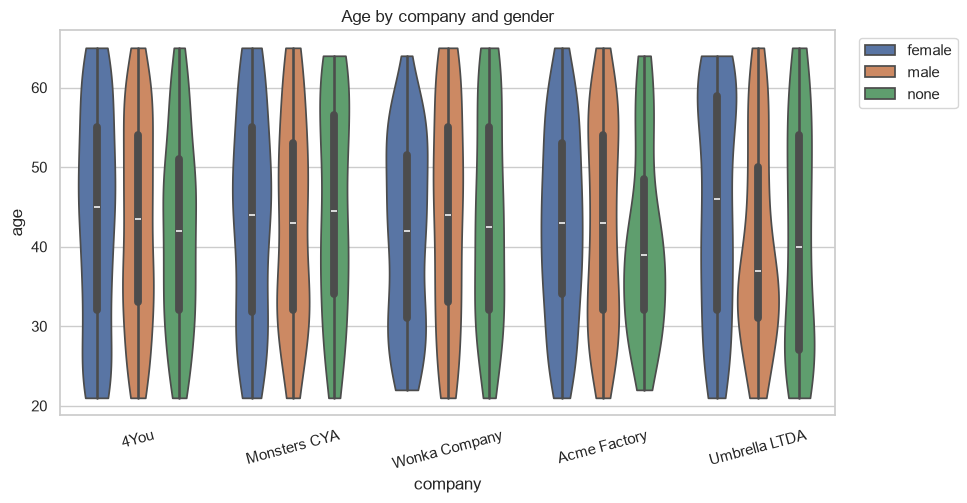

In [22]:
# Chart - 10 visualization code
sns.violinplot(data=users, x="company", y="age", hue="gender", hue_order=["female", "male", "none"], cut=0)
plt.title("Age by company and gender")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.xticks(rotation=15)
plt.show()

##### 1. Why did you pick the specific chart?

A grouped violin plot compares distributions across two categorical dimensions at once.

##### 2. What is/are the insight(s) found from the chart?

Within each company the age distributions of men, women and undeclared users overlap fully. No company/age/gender interaction exists.

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

Confirms that demographic segmentation by company and age doesn't depend on gender. No negative signal.

#### Chart - 11 - Number of flights per user by gender (Behaviour)

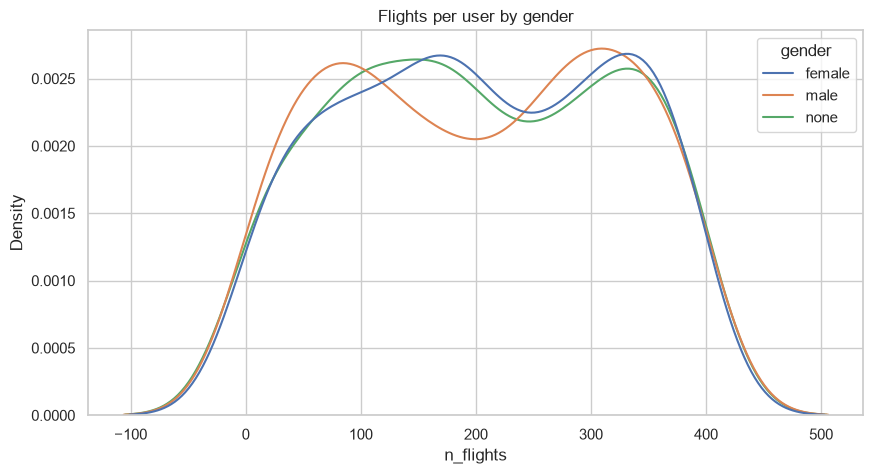

In [23]:
# Chart - 11 visualization code
sns.kdeplot(data=users, x="n_flights", hue="gender", hue_order=["female", "male", "none"], common_norm=False)
plt.title("Flights per user by gender")
plt.show()

##### 1. Why did you pick the specific chart?

Overlaid density curves compare the distribution of a numeric variable across groups with different sizes.

##### 2. What is/are the insight(s) found from the chart?

The curves for all three labels lie on top of each other. Men and women travel equally often.

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. Travel frequency is gender-neutral, so loyalty programmes don't need gender targeting. For the model, flight counts won't help predict gender.

#### Chart - 12 - Average ticket price and first-class share by gender (Behaviour)

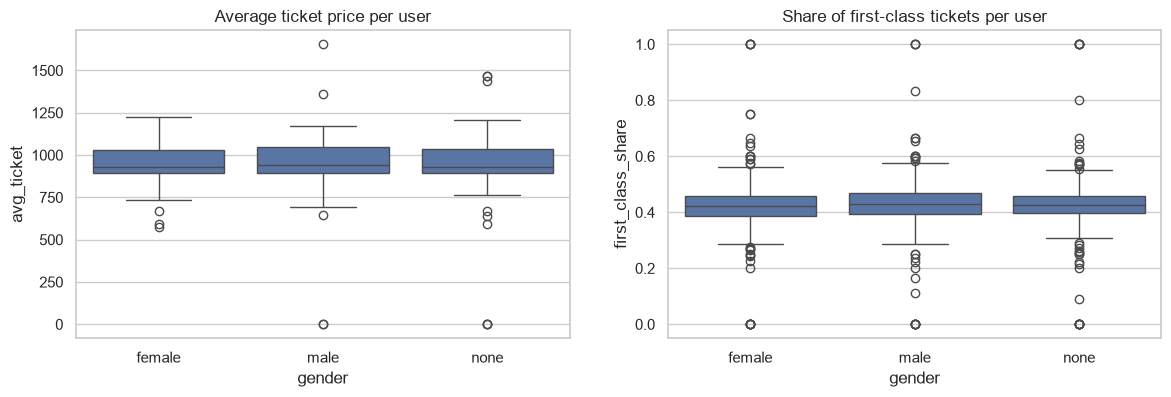

In [24]:
# Chart - 12 visualization code
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.boxplot(data=users, x="gender", y="avg_ticket", ax=ax[0], order=["female", "male", "none"])
ax[0].set_title("Average ticket price per user")
sns.boxplot(data=users, x="gender", y="first_class_share", ax=ax[1], order=["female", "male", "none"])
ax[1].set_title("Share of first-class tickets per user")
plt.show()

##### 1. Why did you pick the specific chart?

Side-by-side box plots compare two spending indicators across groups.

##### 2. What is/are the insight(s) found from the chart?

Average ticket price (≈ R$950) and first-class share (≈ 43%) are the same for every gender label.

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. Premium upsell campaigns should target all genders equally. For modelling, spending behaviour isn't a gender signal.

#### Chart - 13 - Hotel nights by gender (Behaviour)

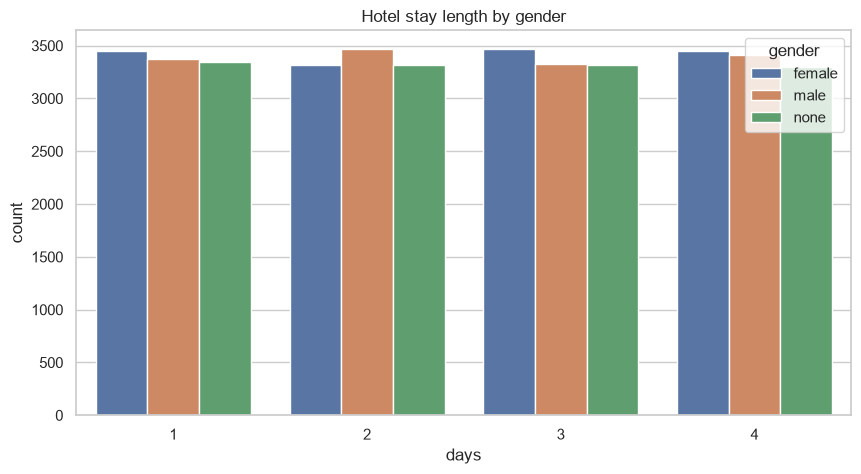

In [25]:
# Chart - 13 visualization code
stays = hotels.merge(users[["code", "gender"]], left_on="userCode", right_on="code")
sns.countplot(data=stays, x="days", hue="gender", hue_order=["female", "male", "none"])
plt.title("Hotel stay length by gender")
plt.show()

##### 1. Why did you pick the specific chart?

A grouped count plot compares a discrete variable (nights per stay: 1–4) across groups.

##### 2. What is/are the insight(s) found from the chart?

Stay lengths are spread evenly (1–4 nights) for every gender label.

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

Hotel packages can be designed without gender assumptions. Together with Charts 11–12, this shows that **behaviour can't predict gender**, which I confirm with the baseline model.

#### Chart - 14 - Correlation Heatmap

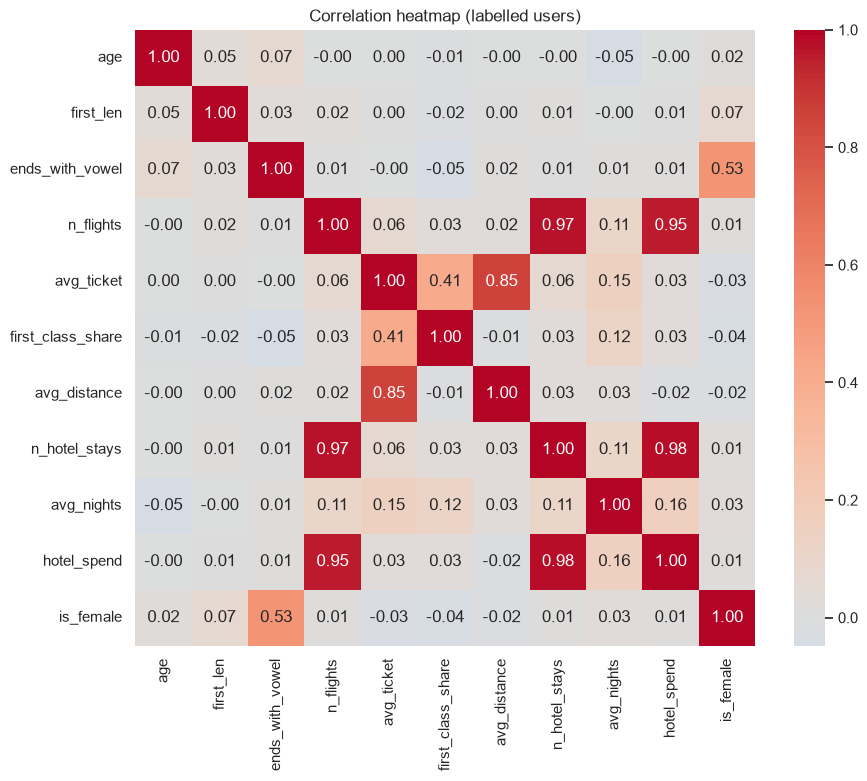

In [26]:
# Correlation Heatmap visualization code
corr_cols = ["age", "first_len", "ends_with_vowel"] + BEHAVIOUR
corr = labelled[corr_cols].assign(is_female=(labelled["gender"] == "female").astype(int)).corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation heatmap (labelled users)")
plt.show()

##### 1. Why did you pick the specific chart?

A correlation heatmap shows which numeric features relate to the target (`is_female`) and to each other in one view.

##### 2. What is/are the insight(s) found from the chart?

`is_female` correlates only with `ends_with_vowel` (≈ +0.53). Age and all behaviour features are ≈ 0. Behaviour features correlate with each other (e.g. number of flights with hotel stays), but none with gender.

#### Chart - 15 - Pair Plot 

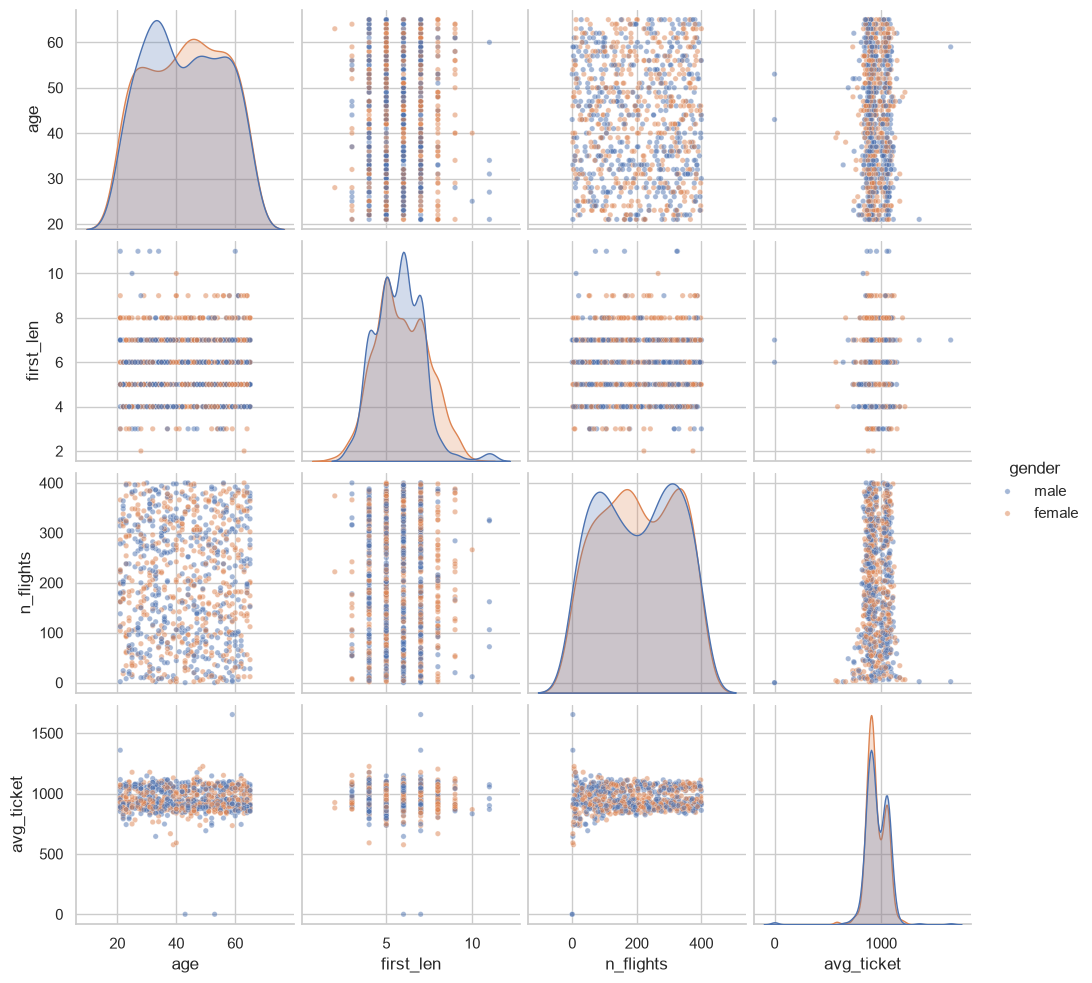

In [27]:
# Pair Plot visualization code
sns.pairplot(labelled[["age", "first_len", "n_flights", "avg_ticket", "gender"]], hue="gender",
             plot_kws={"alpha": 0.5, "s": 15})
plt.show()

##### 1. Why did you pick the specific chart?

A pair plot shows all pairwise relationships, coloured by the target, to look for any combination of numeric features that separates the classes.

##### 2. What is/are the insight(s) found from the chart?

Male and female points overlap completely in every panel. No numeric feature or pair of features separates the classes, so the model has to use the *text* of the name.

## ***5. Hypothesis Testing***

### Based on your chart experiments, define three hypothetical statements from the dataset. In the next three questions, perform hypothesis testing to obtain final conclusion about the statements through your code and statistical testing.

1. The age distribution differs between male, female and undeclared users.
2. Gender depends on the company the user works for.
3. First names ending in "a" are associated with female users.

### Hypothetical Statement - 1

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

* **H0:** The age distribution is the same for male, female and none.
* **H1:** At least one gender label has a different age distribution.

#### 2. Perform an appropriate statistical test.

In [28]:
# Perform Statistical Test to obtain P-Value
groups = [g["age"].values for _, g in users.groupby("gender")]
h_stat, p_value = stats.kruskal(*groups)
print(f"Kruskal-Wallis H = {h_stat:.3f}, p-value = {p_value:.3f}")
print("Reject H0" if p_value < 0.05 else "Fail to reject H0")

Kruskal-Wallis H = 0.969, p-value = 0.616
Fail to reject H0


##### Which statistical test have you done to obtain P-Value?

Kruskal–Wallis H test.

##### Why did you choose the specific statistical test?

Three independent groups and age is uniformly (not normally) distributed, so a rank-based test is safer than ANOVA. p ≈ 0.62 > 0.05, so we **fail to reject H0**: age doesn't differ by gender.

### Hypothetical Statement - 2

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

* **H0:** Gender label and company are independent.
* **H1:** Gender label depends on company.

#### 2. Perform an appropriate statistical test.

In [29]:
# Perform Statistical Test to obtain P-Value
table = pd.crosstab(users["company"], users["gender"])
chi2, p_value, dof, _ = stats.chi2_contingency(table)
print(f"chi2 = {chi2:.2f}, dof = {dof}, p-value = {p_value:.3f}")
print("Reject H0" if p_value < 0.05 else "Fail to reject H0")

chi2 = 8.62, dof = 8, p-value = 0.375
Fail to reject H0


##### Which statistical test have you done to obtain P-Value?

Chi-square test of independence.

##### Why did you choose the specific statistical test?

Both variables are categorical, and every cell of the 5 × 3 contingency table has far more than 5 observations, so the chi-square approximation is valid. p ≈ 0.37 > 0.05, so we **fail to reject H0**: company tells us nothing about gender.

### Hypothetical Statement - 3

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

* **H0:** Ending the first name in "a" is independent of gender.
* **H1:** Names ending in "a" are associated with gender (more female).

#### 2. Perform an appropriate statistical test.

In [30]:
# Perform Statistical Test to obtain P-Value
table = pd.crosstab(labelled["last_letter"] == "a", labelled["gender"])
table.index = ["does not end in 'a'", "ends in 'a'"]
print(table)
chi2, p_value, dof, _ = stats.chi2_contingency(table)
print(f"chi2 = {chi2:.1f}, p-value = {p_value:.2e}")
print("Reject H0" if p_value < 0.05 else "Fail to reject H0")

gender               female  male
does not end in 'a'     281   450
ends in 'a'             167     2
chi2 = 197.7, p-value = 6.49e-45
Reject H0


##### Which statistical test have you done to obtain P-Value?

Chi-square test of independence (2 × 2, with Yates' continuity correction).

##### Why did you choose the specific statistical test?

Both variables are binary categorical and the expected counts are large. p ≈ 6 × 10⁻⁴⁵, so we **reject H0**: name endings are strongly linked to gender. This justifies building the model on character patterns of the first name.

## ***6. Feature Engineering & Data Pre-processing***

### 1. Handling Missing Values

In [31]:
# Handling Missing Values & Missing Value Imputation
print("NaN cells in users:", int(users[["code", "company", "name", "gender", "age"]].isnull().sum().sum()))
print("behaviour NaNs after fillna(0):", int(users[BEHAVIOUR].isnull().sum().sum()))
# gender == "none" is not imputed - those users are excluded from training and scored by the model later

NaN cells in users: 0
behaviour NaNs after fillna(0): 0


#### What all missing value imputation techniques have you used and why did you use those techniques?

There are no NaN values in `users.csv`. Users with no flights or hotel stays get **0** for the behaviour aggregates (zero activity is the true value, not an unknown). The "none" gender label is *not* imputed: those users are left out of training, and at the end I use the model to score them. That is the business use case.

### 2. Handling Outliers

In [32]:
# Handling Outliers & Outlier treatments
for col in ["age", "first_len"] + BEHAVIOUR:
    q1, q3 = users[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    n_out = ((users[col] < q1 - 1.5 * iqr) | (users[col] > q3 + 1.5 * iqr)).sum()
    print(f"{col:<18} IQR outliers: {n_out}")

age                IQR outliers: 0
first_len          IQR outliers: 11
n_flights          IQR outliers: 0
avg_ticket         IQR outliers: 17
first_class_share  IQR outliers: 101
avg_distance       IQR outliers: 6
n_hotel_stays      IQR outliers: 0
avg_nights         IQR outliers: 93
hotel_spend        IQR outliers: 0


##### What all outlier treatment techniques have you used and why did you use those techniques?

I checked each numeric column with the **IQR rule**. Age has no outliers (21–65). The values flagged in name length, first-class share and average nights are real (long first names, users with few trips), and these features are only used in the baseline model with StandardScaler. So I kept them, since capping would distort genuine values. The final model uses text features, where outliers don't apply.

### 3. Categorical Encoding

In [33]:
# Encode your categorical columns
behaviour_X = pd.get_dummies(labelled[["age", "company"] + BEHAVIOUR], columns=["company"], dtype=float)
y = labelled["gender"]                      # target kept as strings - sklearn handles string labels
print(behaviour_X.columns.tolist())

['age', 'n_flights', 'avg_ticket', 'first_class_share', 'avg_distance', 'n_hotel_stays', 'avg_nights', 'hotel_spend', 'company_4You', 'company_Acme Factory', 'company_Monsters CYA', 'company_Umbrella LTDA', 'company_Wonka Company']


#### What all categorical encoding techniques have you used & why did you use those techniques?

`company` is nominal with only 5 levels, so I used **one-hot encoding** for the baseline model. The target is binary and is kept as string labels (`female`/`male`), which scikit-learn handles directly. The name itself is encoded with TF-IDF character n-grams (next section).

### 4. Textual Data Preprocessing 
(It's mandatory for textual dataset i.e., NLP, Sentiment Analysis, Text Clustering etc.)

The user's **name is the main input**, so I applied the text-preprocessing steps that make sense for person names.

#### 1. Expand Contraction

In [34]:
# Expand Contraction
# Names contain no contractions ("don't", "I'm"...), so there is nothing to expand.
# Apostrophes inside names (e.g. O'Brien) are removed with the punctuation step instead.
sample_names = pd.Series(["  Maria  Silva ", "JOHN O'Brien", "anne-marie Smith", "Jo3l  Kim", "Dr. Alex Morgan"])
sample_names

0       Maria  Silva 
1        JOHN O'Brien
2    anne-marie Smith
3           Jo3l  Kim
4     Dr. Alex Morgan
dtype: str

#### 2. Lower Casing

In [35]:
# Lower Casing
lowered = sample_names.str.lower()
lowered

0       maria  silva 
1        john o'brien
2    anne-marie smith
3           jo3l  kim
4     dr. alex morgan
dtype: str

#### 3. Removing Punctuations

In [36]:
# Remove Punctuations
no_punct = lowered.str.translate(str.maketrans("", "", string.punctuation))
no_punct

0      maria  silva 
1        john obrien
2    annemarie smith
3          jo3l  kim
4     dr alex morgan
dtype: str

#### 4. Removing URLs & Removing words and digits contain digits.

In [37]:
# Remove URLs & Remove words and digits contain digits
no_digits = no_punct.str.replace(r"http\S+|www\.\S+", "", regex=True).str.replace(r"\d", "", regex=True)
no_digits

0      maria  silva 
1        john obrien
2    annemarie smith
3           jol  kim
4     dr alex morgan
dtype: str

#### 5. Removing Stopwords & Removing White spaces

In [38]:
# Remove Stopwords
# for names the "stopwords" are titles that carry no gender information on their own
TITLES = {"dr", "mr", "mrs", "ms", "miss", "prof", "sir"}
no_titles = no_digits.apply(lambda s: " ".join(w for w in s.split() if w not in TITLES))
no_titles

0        maria silva
1        john obrien
2    annemarie smith
3            jol kim
4        alex morgan
dtype: str

In [39]:
# Remove White spaces
clean = no_titles.str.split().str.join(" ").str.strip()
clean

0        maria silva
1        john obrien
2    annemarie smith
3            jol kim
4        alex morgan
dtype: object

#### 6. Rephrase Text

In [40]:
# Rephrase Text
# keep only the first name and add start/end markers so n-grams can learn prefixes and suffixes
first = clean.str.split().str[0]
rephrased = "^" + first + "$"
rephrased

0        ^maria$
1         ^john$
2    ^annemarie$
3          ^jol$
4         ^alex$
dtype: object

#### 7. Tokenization

In [41]:
# Tokenization
# word tokens are first/last names; for the model we tokenise the first name into character n-grams
def char_ngrams(token: str, n_min: int = 2, n_max: int = 3):
    return [token[i:i + n] for n in range(n_min, n_max + 1) for i in range(len(token) - n + 1)]


print(clean.str.split().tolist()[:2])
print(char_ngrams("^maria$"))

[['maria', 'silva'], ['john', 'obrien']]
['^m', 'ma', 'ar', 'ri', 'ia', 'a$', '^ma', 'mar', 'ari', 'ria', 'ia$']


#### 8. Text Normalization

In [42]:
# Normalizing Text (i.e., Stemming, Lemmatization etc.)
# Stemming/lemmatisation would chop name endings ("maria" -> "mari") and destroy the gender signal,
# so the only normalisation is Unicode -> ASCII (e.g. "José" -> "jose").
import unicodedata


def normalise(text: str) -> str:
    return unicodedata.normalize("NFKD", text).encode("ascii", "ignore").decode()


print(normalise("José"), normalise("Zoë"))


def clean_first_name(names) -> pd.Series:
    """Full preprocessing used by the model: lower, strip punctuation/digits/titles, first name, markers."""
    s = pd.Series(names).astype(str).map(normalise).str.lower()
    s = s.str.translate(str.maketrans("", "", string.punctuation)).str.replace(r"\d", "", regex=True)
    s = s.apply(lambda t: " ".join(w for w in t.split() if w not in TITLES))
    return "^" + s.str.split().str[0].fillna("") + "$"


clean_first_name(sample_names)

Jose Zoe


0        ^maria$
1         ^john$
2    ^annemarie$
3          ^jol$
4         ^alex$
dtype: object

##### Which text normalization technique have you used and why?

I used **Unicode-to-ASCII normalisation** and **lower-casing**, and deliberately skipped stemming and lemmatisation. Those are designed for dictionary words: a stemmer would turn "maria" into "mari" and remove exactly the suffix that carries the gender signal.

#### 9. Part of speech tagging

In [43]:
# POS Taging
# Every token in a name is a proper noun (NNP), so POS tags add no information for this task.
pos_tags = [(token, "NNP") for token in clean.iloc[0].split()]
pos_tags

[('maria', 'NNP'), ('silva', 'NNP')]

#### 10. Text Vectorization

In [44]:
# Vectorizing Text
vectorizer = TfidfVectorizer(analyzer="char", ngram_range=(2, 4), sublinear_tf=True)
name_matrix = vectorizer.fit_transform(clean_first_name(labelled["name"]))
print("TF-IDF matrix:", name_matrix.shape)
print("sample features:", vectorizer.get_feature_names_out()[:15])

TF-IDF matrix: (900, 2985)
sample features: ['^a' '^aa' '^aar' '^ab' '^abb' '^abd' '^abr' '^ad' '^ada' '^add' '^adr'
 '^ag' '^agn' '^al' '^ala']


##### Which text vectorization technique have you used and why?

**TF-IDF on character n-grams** (2–4 characters, with sublinear TF). Word-level bag-of-words would treat every name as an unrelated token and fail on names it has never seen. Character n-grams break names into pieces like `a$`, `ine$` and `^jo`, which are shared across names, so the model generalises. TF-IDF also down-weights n-grams that appear in almost every name.

### 4. Feature Manipulation & Selection

#### 1. Feature Manipulation

In [45]:
# Manipulate Features to minimize feature correlation and create new features
# behaviour feature set: drop avg_distance (≈ redundant with avg_ticket / first_class_share)
print(labelled[["avg_ticket", "first_class_share", "avg_distance"]].corr().round(2))
BEHAVIOUR_SELECTED = ["age", "n_flights", "avg_ticket", "first_class_share", "n_hotel_stays", "avg_nights",
                      "hotel_spend"]

                   avg_ticket  first_class_share  avg_distance
avg_ticket               1.00               0.41          0.85
first_class_share        0.41               1.00         -0.01
avg_distance             0.85              -0.01          1.00


#### 2. Feature Selection

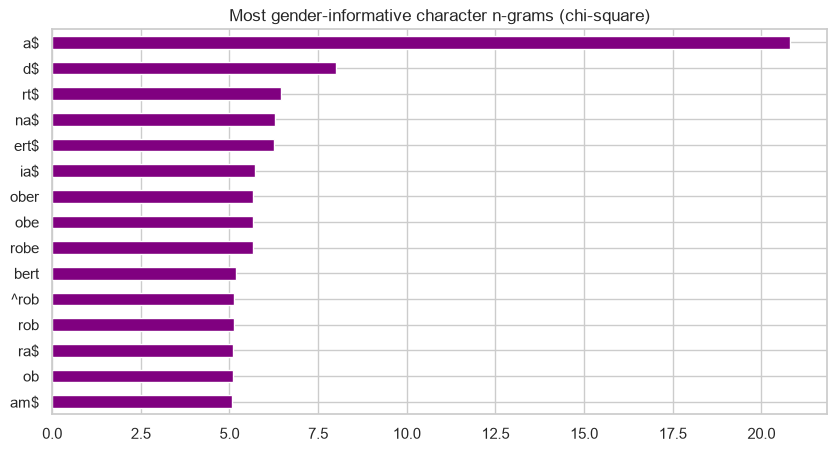

In [46]:
# Select your features wisely to avoid overfitting
# chi-square score of each character n-gram vs gender - which pieces of a name are most informative?
from sklearn.feature_selection import chi2 as chi2_score

scores, _ = chi2_score(name_matrix, labelled["gender"])
top = pd.Series(scores, index=vectorizer.get_feature_names_out()).sort_values(ascending=False).head(15)
top.plot(kind="barh", color="purple")
plt.gca().invert_yaxis()
plt.title("Most gender-informative character n-grams (chi-square)")
plt.show()

##### What all feature selection methods have you used  and why?

* **Statistical tests** (Hypotheses 1–2) and **correlation analysis** (Chart 14) showed that age, company and behaviour have no relationship with gender, so they are only used in the baseline model to prove that point.
* **Chi-square scoring** of the character n-grams shows which pieces of a name are most informative.
* **L2 regularisation** in Logistic Regression (the `C` parameter, tuned by CV) acts as embedded feature selection over the thousands of n-grams and prevents overfitting to rare ones.

##### Which all features you found important and why?

The most informative features are **name endings**: `a$`, `na$`, `ia$` and `ra$` for female, and `d$`, `rt$` and `am$` for male. Pieces of very common names such as `robe`/`bert` (Robert) also rank high. This matches Chart 7 and Hypothesis 3. None of the demographic or behaviour features matter.

### 5. Data Transformation

#### Do you think that your data needs to be transformed? If yes, which transformation have you used. Explain Why?

In [47]:
# Transform Your data
# behaviour features are right-skewed money/counts -> log1p for the baseline model
print(labelled[["hotel_spend", "n_hotel_stays"]].skew().round(2))
log_cols = ["hotel_spend", "n_hotel_stays", "n_flights"]
behaviour_X[log_cols] = np.log1p(behaviour_X[log_cols])

hotel_spend      0.14
n_hotel_stays    0.07
dtype: float64


For the baseline model I applied **log1p** to the right-skewed count and money features (hotel spend, number of stays, flights) to reduce the influence of very active users. For the text model, the TF-IDF with sublinear TF (log of term frequency) is already the transformation.

### 6. Data Scaling

In [48]:
# Scaling your data
scaler = StandardScaler()          # used inside the baseline pipeline below

##### Which method have you used to scale you data and why?

**StandardScaler** for the numeric baseline features, because Logistic Regression's regularisation is scale-sensitive. TF-IDF vectors are already L2-normalised per name, so the text model needs no extra scaling.

### 7. Dimesionality Reduction

##### Do you think that dimensionality reduction is needed? Explain Why?

No. The TF-IDF matrix has a few thousand sparse columns, but linear models with L2 regularisation handle sparse high-dimensional text very well. Reducing it with SVD would mix n-grams into abstract components and lose the interpretability of the coefficients.

In [49]:
# DImensionality Reduction (If needed)
# Not needed - see explanation above.

##### Which dimensionality reduction technique have you used and why? (If dimensionality reduction done on dataset.)

None.

### 8. Data Splitting

In [50]:
# Split your data to train and test. Choose Splitting ratio wisely.
names = labelled["name"]
idx_train, idx_test = train_test_split(labelled.index, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
y_train, y_test = y.loc[idx_train], y.loc[idx_test]
print(f"train: {len(idx_train)} users | test: {len(idx_test)} users")
print(y_train.value_counts(normalize=True).round(3).to_dict())

# for the "unseen first name" check, all users sharing a first name stay in the same fold
name_groups = clean_first_name(names)

train: 720 users | test: 180 users


{'male': 0.503, 'female': 0.497}


##### What data splitting ratio have you used and why? 

An **80/20 stratified split** (720 train / 180 test users). Stratification keeps the 50/50 class balance in both sets, and with only 900 labelled users, 20% is the smallest test set that still gives a stable estimate. For hyperparameter tuning I use stratified 5-fold CV on the training set, and a **GroupKFold by first name** measures accuracy on names the model has never seen.

### 9. Handling Imbalanced Dataset

##### Do you think the dataset is imbalanced? Explain Why.

No. Among labelled users there are 452 male and 448 female, a 50.2 / 49.8 split. No resampling or class weights are needed.

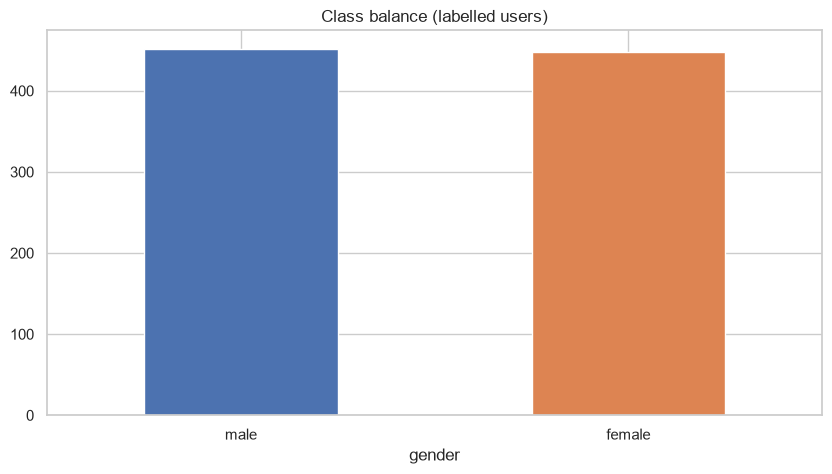

In [51]:
# Handling Imbalanced Dataset (If needed)
y.value_counts().plot(kind="bar", rot=0, color=["#4C72B0", "#DD8452"], title="Class balance (labelled users)")
plt.show()

##### What technique did you use to handle the imbalance dataset and why? (If needed to be balanced)

None needed; stratified splitting is enough to keep the balance in every fold.

## ***7. ML Model Implementation***

In [52]:
# helpers shared by all models
results = {}
cv = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)


def evaluate(name, model, X_te, y_te):
    """Classification metrics on the test set + store for the final comparison."""
    pred = model.predict(X_te)
    proba = model.predict_proba(X_te)[:, list(model.classes_).index("male")]
    scores = {"accuracy": accuracy_score(y_te, pred), "precision": precision_score(y_te, pred, pos_label="female"),
              "recall": recall_score(y_te, pred, pos_label="female"), "f1_macro": f1_score(y_te, pred, average="macro"),
              "roc_auc": roc_auc_score((y_te == "male").astype(int), proba)}
    results[name] = scores
    return pd.Series(scores).round(4)


def plot_scores(model, X_te, y_te, title):
    """Metric bars + confusion matrix + ROC curve."""
    fig, ax = plt.subplots(1, 3, figsize=(17, 4))
    s = pd.Series(results[title])
    s.plot(kind="bar", ax=ax[0], color="#4C72B0", rot=20, ylim=(0, 1), title=title)
    for c in ax[0].containers:
        ax[0].bar_label(c, fmt="%.2f")
    ConfusionMatrixDisplay.from_estimator(model, X_te, y_te, ax=ax[1], cmap="Blues", colorbar=False)
    RocCurveDisplay.from_estimator(model, X_te, y_te, ax=ax[2],
                                   pos_label="male")
    ax[2].plot([0, 1], [0, 1], "k--", alpha=0.4)
    plt.tight_layout()
    plt.show()

### ML Model - 1 - Logistic Regression on demographics + travel behaviour (baseline)

In [53]:
# ML Model - 1 Implementation
X_beh_train, X_beh_test = behaviour_X.loc[idx_train], behaviour_X.loc[idx_test]
behaviour_model = Pipeline([("scale", StandardScaler()), ("clf", LogisticRegression(max_iter=1000))])

# Fit the Algorithm
behaviour_model.fit(X_beh_train, y_train)

# Predict on the model
evaluate("Behaviour LogReg", behaviour_model, X_beh_test, y_test)

accuracy     0.5000
precision    0.5000
recall       0.5778
f1_macro     0.4970
roc_auc      0.4763
dtype: float64

#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

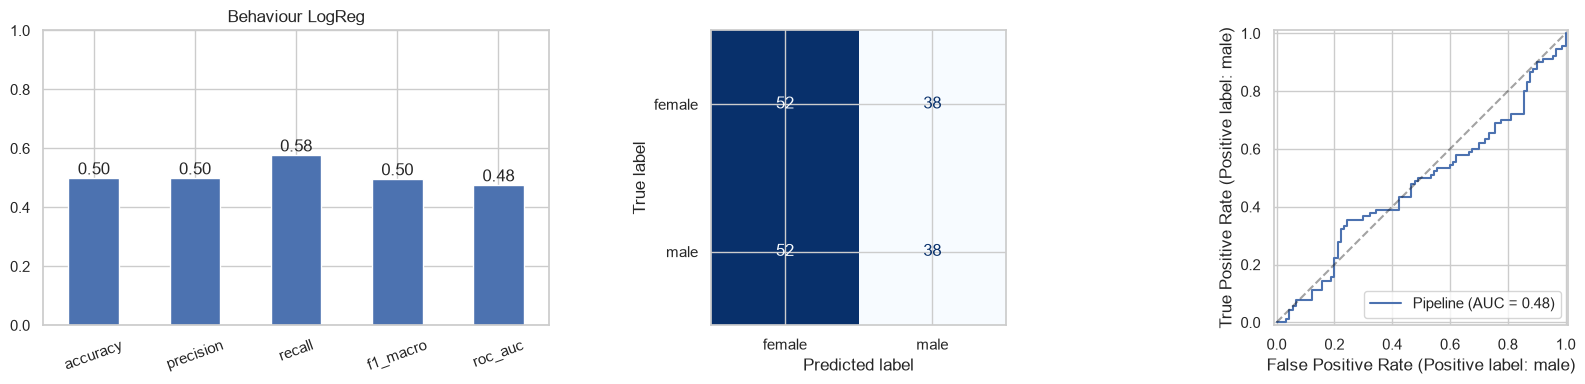

In [54]:
# Visualizing evaluation Metric Score chart
plot_scores(behaviour_model, X_beh_test, y_test, "Behaviour LogReg")

**Logistic Regression** models the log-odds of the class as a linear combination of the features. Here the features are age, company and the travel-behaviour aggregates. The model scores about **50% accuracy and a ROC-AUC near 0.5**, no better than random guessing. The ROC curve follows the diagonal. This confirms the EDA: how a person travels says nothing about their gender in this data.

#### 2. Cross- Validation & Hyperparameter Tuning

In [55]:
# ML Model - 1 Implementation with hyperparameter optimization techniques (i.e., GridSearch CV, RandomSearch CV, Bayesian Optimization etc.)
behaviour_grid = GridSearchCV(behaviour_model, {"clf__C": [0.01, 0.1, 1, 10]}, cv=cv, scoring="f1_macro")

# Fit the Algorithm
behaviour_grid.fit(X_beh_train, y_train)
print("best params:", behaviour_grid.best_params_, "| CV macro-F1:", round(behaviour_grid.best_score_, 3))

# Predict on the model
evaluate("Behaviour LogReg (tuned)", behaviour_grid.best_estimator_, X_beh_test, y_test)

best params: {'clf__C': 10} | CV macro-F1: 0.494


accuracy     0.5056
precision    0.5048
recall       0.5889
f1_macro     0.5021
roc_auc      0.4790
dtype: float64

##### Which hyperparameter optimization technique have you used and why?

**GridSearchCV** over the regularisation strength `C` with stratified 5-fold CV. There's one hyperparameter and a tiny dataset, so an exhaustive grid is cheap.

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

No meaningful improvement: CV macro-F1 stays around 0.5 for every `C`. Tuning can't create a signal that isn't in the features, so this model is only a baseline.

### ML Model - 2 - Multinomial Naive Bayes on character n-grams

In [56]:
# ML Model - 2 Implementation
X_name_train, X_name_test = names.loc[idx_train], names.loc[idx_test]
nb_model = Pipeline([("clean", FunctionTransformer(clean_first_name)),
                     ("tfidf", TfidfVectorizer(analyzer="char", ngram_range=(2, 4), sublinear_tf=True)),
                     ("clf", MultinomialNB(alpha=1.0))])
# Fit the Algorithm
nb_model.fit(X_name_train, y_train)
# Predict on the model
evaluate("Naive Bayes", nb_model, X_name_test, y_test)

accuracy     0.8611
precision    0.8736
recall       0.8444
f1_macro     0.8611
roc_auc      0.9427
dtype: float64

#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

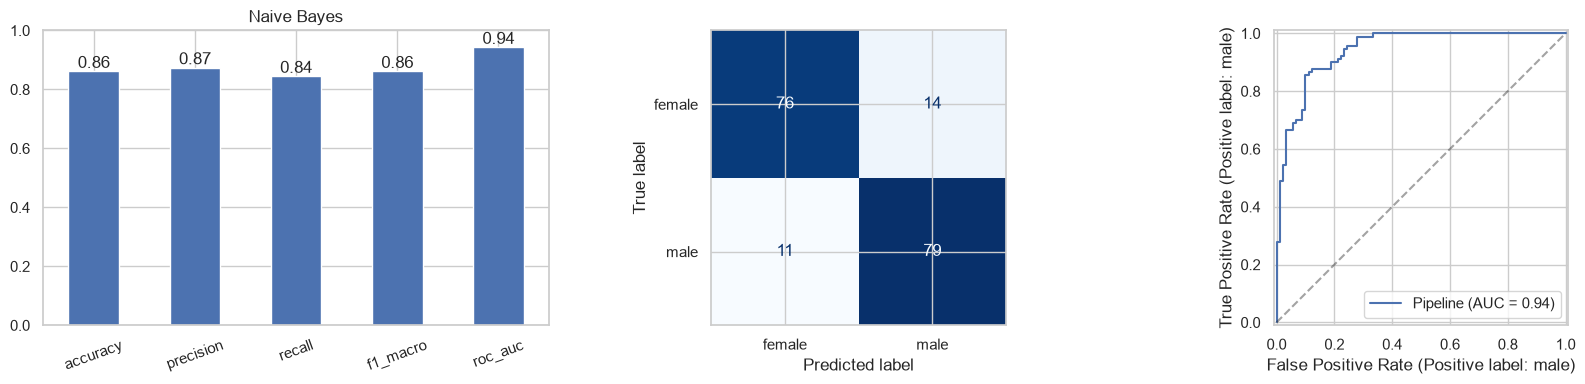

In [57]:
# Visualizing evaluation Metric Score chart
plot_scores(nb_model, X_name_test, y_test, "Naive Bayes")

**Multinomial Naive Bayes** applies Bayes' theorem, assuming the n-gram features are conditionally independent given the class. It is a classic, very fast text classifier. Using only the name, accuracy jumps from ≈ 0.50 to ≈ 0.86 and ROC-AUC to ≈ 0.94, which shows the first name carries the gender signal.

#### 2. Cross- Validation & Hyperparameter Tuning

In [58]:
# ML Model - 2 Implementation with hyperparameter optimization techniques (i.e., GridSearch CV, RandomSearch CV, Bayesian Optimization etc.)
nb_grid = GridSearchCV(nb_model, {"tfidf__ngram_range": [(1, 3), (2, 4), (1, 5)], "clf__alpha": [0.1, 0.3, 1.0]},
                       cv=cv, scoring="f1_macro", n_jobs=-1)
# Fit the Algorithm
nb_grid.fit(X_name_train, y_train)
print("best params:", nb_grid.best_params_, "| CV macro-F1:", round(nb_grid.best_score_, 3))
# Predict on the model
nb_tuned = nb_grid.best_estimator_
evaluate("Naive Bayes (tuned)", nb_tuned, X_name_test, y_test)

best params: {'clf__alpha': 1.0, 'tfidf__ngram_range': (1, 5)} | CV macro-F1: 0.872


accuracy     0.8722
precision    0.8941
recall       0.8444
f1_macro     0.8721
roc_auc      0.9486
dtype: float64

##### Which hyperparameter optimization technique have you used and why?

**GridSearchCV** (stratified 5-fold) over the n-gram range and the smoothing parameter `alpha`. The grid is small (9 combinations) and each fit takes milliseconds, so an exhaustive search is the simplest reliable choice.

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

Yes, a small one: the search kept `alpha = 1.0` but chose longer n-grams (1–5 characters), which capture whole endings. Accuracy rose from 0.861 to 0.872 and macro-F1 from 0.861 to 0.872 (CV macro-F1 0.872).

#### 3. Explain each evaluation metric's indication towards business and the business impact pf the ML model used.

* **Accuracy**: the share of users whose gender is predicted correctly. It's easy to communicate and meaningful here because the classes are balanced.
* **Precision (female)**: of the users we label female, how many really are. High precision avoids sending gender-targeted offers to the wrong people, which can annoy customers.
* **Recall (female)**: of all female users, how many we find. High recall means fewer customers miss relevant offers.
* **Macro-F1**: the balance of precision and recall averaged over both classes. It's my main selection metric because it treats both genders equally.
* **ROC-AUC**: how well the predicted probabilities rank the classes, independent of the threshold. It matters because the business uses the probability to decide when to answer "uncertain".

### ML Model - 3 - Logistic Regression on character n-grams

In [59]:
# ML Model - 3 Implementation
lr_model = Pipeline([("clean", FunctionTransformer(clean_first_name)),
                     ("tfidf", TfidfVectorizer(analyzer="char", ngram_range=(2, 4), sublinear_tf=True)),
                     ("clf", LogisticRegression(C=1.0, max_iter=2000))])
# Fit the Algorithm
lr_model.fit(X_name_train, y_train)
# Predict on the model
evaluate("Char n-gram LogReg", lr_model, X_name_test, y_test)

accuracy     0.8667
precision    0.8929
recall       0.8333
f1_macro     0.8665
roc_auc      0.9493
dtype: float64

#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

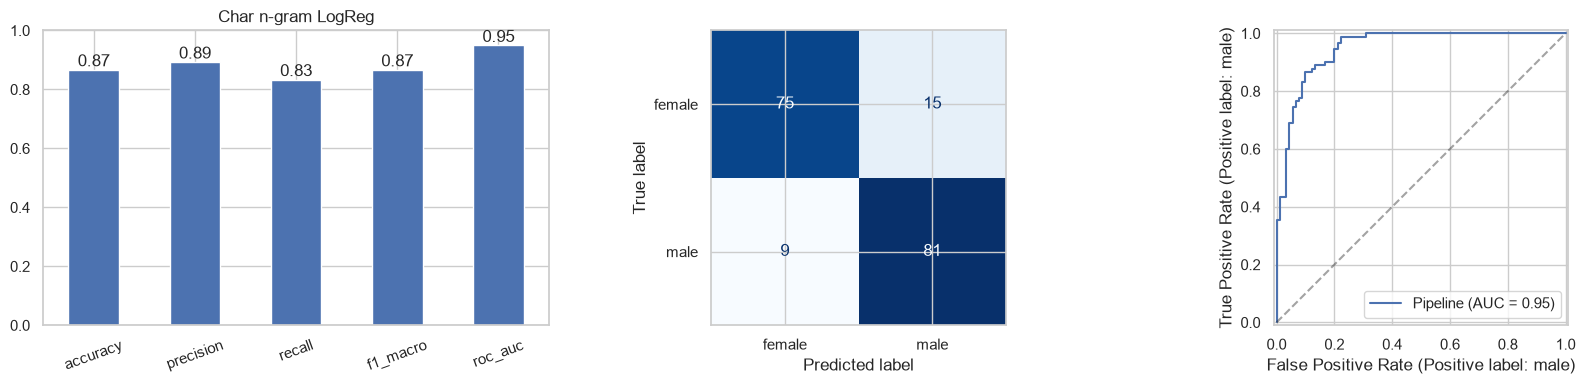

In [60]:
# Visualizing evaluation Metric Score chart
plot_scores(lr_model, X_name_test, y_test, "Char n-gram LogReg")

**Logistic Regression on TF-IDF character n-grams** learns a weight for every name piece and combines them into a probability. Unlike Naive Bayes it doesn't assume the n-grams are independent ("a$" and "ia$" overlap), and its probabilities are better calibrated, which matters for the "uncertain" threshold.

#### 2. Cross- Validation & Hyperparameter Tuning

In [61]:
# ML Model - 3 Implementation with hyperparameter optimization techniques (i.e., GridSearch CV, RandomSearch CV, Bayesian Optimization etc.)
lr_grid = GridSearchCV(lr_model, {"tfidf__ngram_range": [(1, 3), (2, 4), (1, 5)], "clf__C": [0.5, 1, 5, 10]},
                       cv=cv, scoring="f1_macro", n_jobs=-1)
# Fit the Algorithm
lr_grid.fit(X_name_train, y_train)
print("best params:", lr_grid.best_params_, "| CV macro-F1:", round(lr_grid.best_score_, 3))
# Predict on the model
lr_tuned = lr_grid.best_estimator_
evaluate("Char n-gram LogReg (tuned)", lr_tuned, X_name_test, y_test)

best params: {'clf__C': 10, 'tfidf__ngram_range': (1, 5)} | CV macro-F1: 0.903


accuracy     0.8889
precision    0.9167
recall       0.8556
f1_macro     0.8888
roc_auc      0.9604
dtype: float64

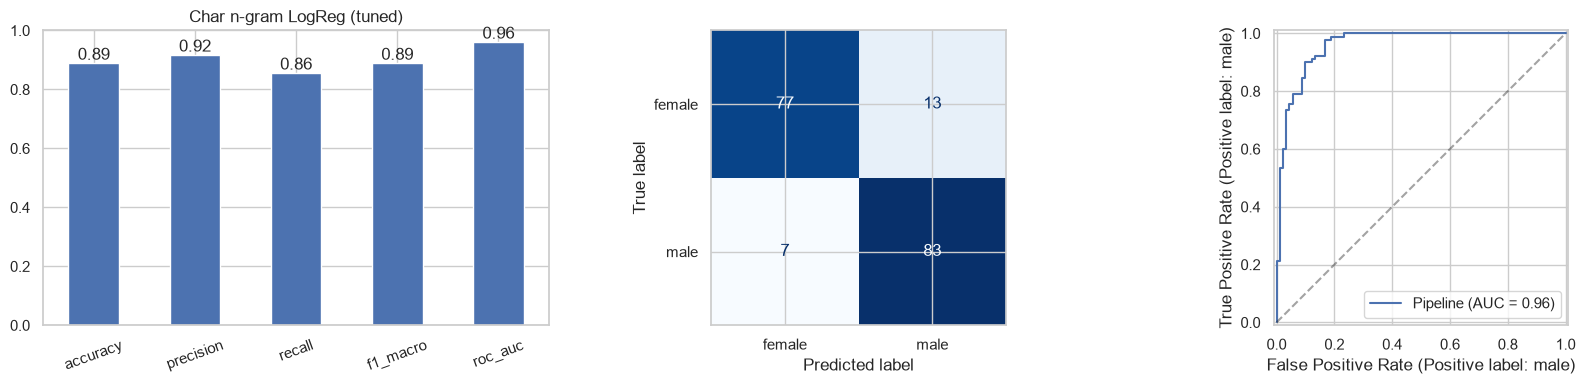

              precision    recall  f1-score   support

      female       0.92      0.86      0.89        90
        male       0.86      0.92      0.89        90

    accuracy                           0.89       180
   macro avg       0.89      0.89      0.89       180
weighted avg       0.89      0.89      0.89       180



In [62]:
plot_scores(lr_tuned, X_name_test, y_test, "Char n-gram LogReg (tuned)")
print(classification_report(y_test, lr_tuned.predict(X_name_test)))

##### Which hyperparameter optimization technique have you used and why?

**GridSearchCV** with stratified 5-fold CV over the n-gram range and the inverse regularisation `C` (12 combinations, each trains in milliseconds), optimising macro-F1.

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

Yes. The search picked n-grams of 1–5 characters and a weaker penalty (C = 10), which lifted CV macro-F1 to ≈ 0.90 and test accuracy to ≈ 0.89 (ROC-AUC ≈ 0.96). Longer n-grams capture whole endings such as "ette$", and the weaker penalty lets the model trust these strong patterns.

### Model comparison and robustness checks

,accuracy,precision,recall,f1_macro,roc_auc
Behaviour LogReg,0.500,0.500,0.578,0.497,0.476
Behaviour LogReg (tuned),0.506,0.505,0.589,0.502,0.479
Naive Bayes,0.861,0.874,0.844,0.861,0.943
Char n-gram LogReg,0.867,0.893,0.833,0.867,0.949
Naive Bayes (tuned),0.872,0.894,0.844,0.872,0.949
Char n-gram LogReg (tuned),0.889,0.917,0.856,0.889,0.960


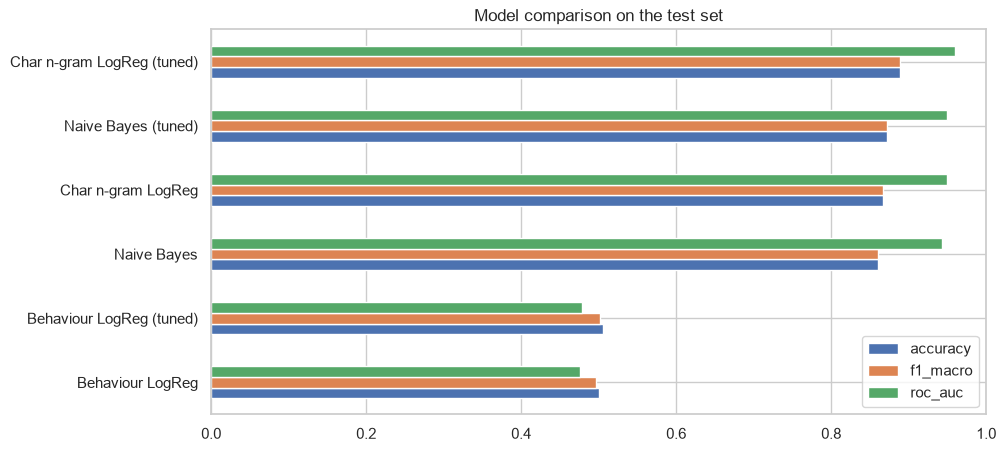

accuracy on unseen first names: 0.740 ± 0.030


In [63]:
comparison = pd.DataFrame(results).T.round(3).sort_values("f1_macro")
display(comparison)
comparison[["accuracy", "f1_macro", "roc_auc"]].plot(kind="barh", figsize=(10, 5), xlim=(0, 1))
plt.title("Model comparison on the test set")
plt.show()

# accuracy on first names the model has never seen (GroupKFold by first name)
best_params = lr_grid.best_params_
unseen_acc = cross_val_score(lr_model.set_params(**best_params), names, y, cv=GroupKFold(5), groups=name_groups)
print(f"accuracy on unseen first names: {unseen_acc.mean():.3f} ± {unseen_acc.std():.3f}")

,threshold,coverage,accuracy_on_covered
0,0.5,1.000,0.889
1,0.6,0.939,0.923
2,0.7,0.867,0.936
3,0.8,0.750,0.970
4,0.9,0.522,0.989


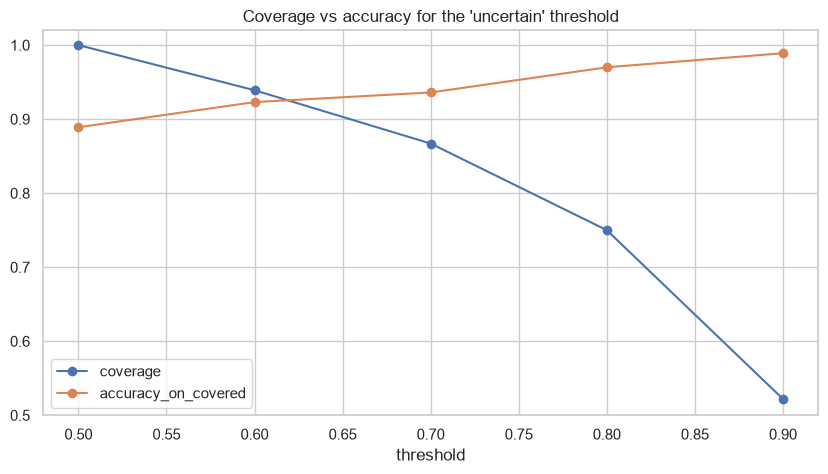

In [64]:
# business view: how many users can we label at each confidence threshold, and how accurate are we?
proba = lr_tuned.predict_proba(X_name_test).max(axis=1)
pred = lr_tuned.predict(X_name_test)
rows = []
for t in [0.5, 0.6, 0.7, 0.8, 0.9]:
    mask = proba >= t
    rows.append({"threshold": t, "coverage": mask.mean(), "accuracy_on_covered": (pred[mask] == y_test.values[mask]).mean()})
threshold_table = pd.DataFrame(rows).round(3)
display(threshold_table)
threshold_table.plot(x="threshold", y=["coverage", "accuracy_on_covered"], marker="o", ylim=(0.5, 1.02))
plt.title("Coverage vs accuracy for the 'uncertain' threshold")
plt.show()

* The name-based models are far ahead of the behaviour baseline (≈ 0.89 vs ≈ 0.50 accuracy).
* On **first names never seen in training** the final model still gets ≈ 0.74 accuracy, learned purely from spelling patterns.
* The threshold table shows the business trade-off: at the **60% threshold** used by the API, 94% of users get a label with **92% accuracy**. At 80%, coverage drops to 75% but accuracy reaches 97%.

### 1. Which Evaluation metrics did you consider for a positive business impact and why?

**Macro-F1** is the selection metric because it weighs errors on both genders equally (no group is favoured). **ROC-AUC** confirms that the probabilities rank well, which is what the "uncertain" threshold relies on. **Coverage vs accuracy** translates the model into business terms: how many profiles we can fill, and how reliably.

### 2. Which ML model did you choose from the above created models as your final prediction model and why?

The **tuned character n-gram Logistic Regression**:
1. Best macro-F1 and accuracy (≈ 0.89) and the best ROC-AUC (≈ 0.96) on the test set.
2. Well-calibrated probabilities, needed for the 60% "uncertain" rule.
3. Tiny and fast (≈ 40 KB, sub-millisecond predictions), ideal for the Flask API container.
4. Fully explainable: every n-gram has a readable weight (below).

### 3. Explain the model which you have used and the feature importance using any model explainability tool?

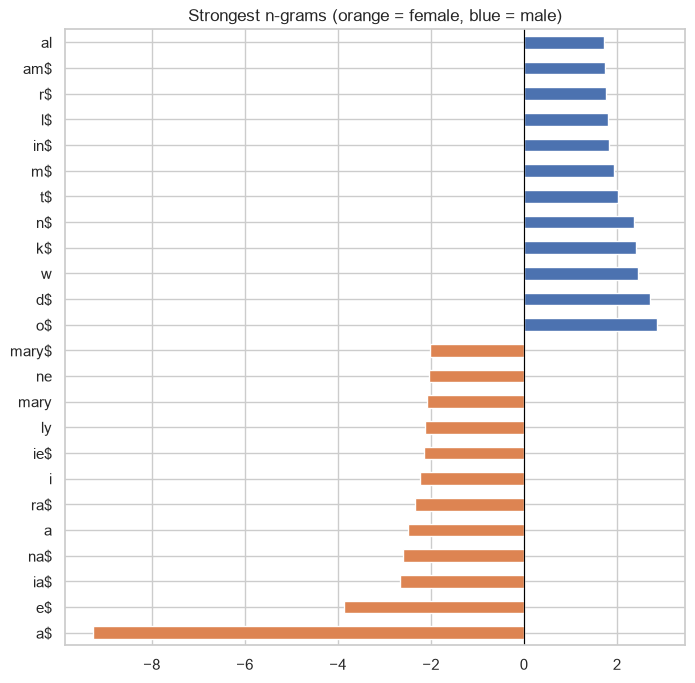

Maria Silva    -> {'female': np.float64(0.986), 'male': np.float64(0.014)}
John Smith     -> {'female': np.float64(0.026), 'male': np.float64(0.974)}
Jordan Lee     -> {'female': np.float64(0.098), 'male': np.float64(0.902)}
Ashley Brown   -> {'female': np.float64(0.907), 'male': np.float64(0.093)}


In [65]:
# coefficients of the logistic regression = how much each n-gram pushes towards "male" (+) or "female" (-)
vec = lr_tuned.named_steps["tfidf"]
coefs = pd.Series(lr_tuned.named_steps["clf"].coef_[0], index=vec.get_feature_names_out())
top_feats = pd.concat([coefs.nsmallest(12), coefs.nlargest(12)])
colors = ["#DD8452" if v < 0 else "#4C72B0" for v in top_feats]
top_feats.plot(kind="barh", color=colors, figsize=(8, 8))
plt.title("Strongest n-grams (orange = female, blue = male)")
plt.axvline(0, color="black", linewidth=0.8)
plt.show()

# explain a few individual predictions
for name in ["Maria Silva", "John Smith", "Jordan Lee", "Ashley Brown"]:
    p = lr_tuned.predict_proba([name])[0]
    print(f"{name:<14} -> {dict(zip(lr_tuned.classes_, p.round(3)))}")

The model is a linear model over character n-grams, so its **coefficients are the explanation**: each n-gram adds to or subtracts from the log-odds of "male".
* **Female** is driven by endings like `a$`, `e$`, `ia$`, `na$`, `ra$` and `ie$`.
* **Male** is driven by endings like `o$`, `d$`, `k$`, `n$`, `t$` and `m$`.
* For a single prediction, the n-grams present in the name explain the result: "Maria" contains `ia$`/`a$` and gets 99% female, while unisex names like "Taylor" have mixed signals and fall below the 60% threshold, so the API answers "uncertain".

### Scoring the users who did not declare a gender

In [66]:
# business use case: fill in profiles where gender = "none"
none_proba = lr_tuned.predict_proba(unlabelled["name"])
unlabelled["predicted"] = np.where(none_proba.max(axis=1) >= 0.6, lr_tuned.classes_[none_proba.argmax(axis=1)],
                                   "uncertain")
unlabelled["confidence"] = none_proba.max(axis=1).round(3)
print(unlabelled["predicted"].value_counts())
unlabelled[["name", "predicted", "confidence"]].head(10)

predicted
female       211
male         198
uncertain     31
Name: count, dtype: int64


,name,predicted,confidence
5,Trina Thomas,female,0.953
8,Jack Sabo,male,0.873
9,Debbie Helms,female,0.919
13,Irene Tucker,female,0.932
17,Victor Tribbett,male,0.863
18,Tanya Orourke,female,0.876
31,Christopher Elliott,male,0.954
35,Helen Selby,female,0.926
36,Anna Rodriguez,female,0.990
37,Denise Newton,female,0.732


## ***8.*** ***Future Work (Optional)***

### 1. Save the best performing ml model in a pickle file or joblib file format for deployment process.

In [67]:
# Save the File
MODEL_FILE = "gender_model_notebook.joblib"
joblib.dump(lr_tuned, MODEL_FILE, compress=3)
print(f"saved {MODEL_FILE} ({os.path.getsize(MODEL_FILE) / 1024:.0f} KB)")
# production artefact: models/gender_model.joblib, built by src/travel_ml/train_classifier.py and logged to MLflow

saved gender_model_notebook.joblib (40 KB)


### 2. Again Load the saved model file and try to predict unseen data for a sanity check.

In [68]:
# Load the File and predict unseen data.
loaded = joblib.load(MODEL_FILE)
new_users = ["Isabella Costa", "Ethan Walker", "  dr. SOFIA  ramos", "Taylor Reed", "Gabriel Souza"]
proba = loaded.predict_proba(new_users)
pd.DataFrame({"name": new_users,
              "prediction": np.where(proba.max(axis=1) >= 0.6, loaded.classes_[proba.argmax(axis=1)], "uncertain"),
              "confidence": proba.max(axis=1).round(3)})

,name,prediction,confidence
0,Isabella Costa,female,0.935
1,Ethan Walker,male,0.615
2,dr. SOFIA ramos,female,0.981
3,Taylor Reed,uncertain,0.566
4,Gabriel Souza,male,0.720


### ***Congrats! Your model is successfully created and ready for deployment on a live server for a real user interaction !!!***

In the repo the same model is trained by `src/travel_ml/train_classifier.py` (GridSearchCV, logged to the MLflow experiment `gender-classification` and registered as `gender-classifier`), retrained weekly by the Airflow DAG and served by the Flask API:

```bash
curl -X POST http://localhost:5000/predict/gender -H "Content-Type: application/json" \
     -d '{"names": ["Maria Silva", "John Smith"]}'
```

# **Conclusion**

* A third of users (440) have no declared gender. Since the same first names appear under "none" and under male/female, "none" is a missing label, not a class. I framed the problem as **male vs female with an "uncertain" fallback**.
* Age, company and all travel-behaviour features are unrelated to gender (hypothesis tests p > 0.3; baseline model ≈ 50% accuracy, no better than chance).
* The **first name** carries the signal (names ending in "a" are 99% female). With NLP preprocessing and **character n-gram TF-IDF**, a tuned **Logistic Regression** reaches ≈ 0.89 accuracy / macro-F1 and ≈ 0.96 ROC-AUC, and ≈ 0.74 on names it has never seen.
* The model is small, fast and explainable. It is served by the Flask API, available in Streamlit, tracked in MLflow and retrained by Airflow.

**Ethical note:** gender inferred from a name is a guess, not an identity. In production it should only fill gaps for aggregate analytics or opt-in personalisation, never override what users declare, and always come with its confidence score.

**Future work:** add more labelled names (e.g. public name–gender datasets) to improve unseen-name accuracy, support multilingual names, and monitor prediction confidence over time to detect drift in the user base.

### ***Hurrah! You have successfully completed your Machine Learning Capstone Project !!!***